## Feature Selection

> Shows feature elimination decisions (variance threshold, correlation pruning, leakage checks). Logs results in a table (results/feature_selection.csv).

In [124]:
import numpy as np
# Set numpy to print only 2 decimal digits for neatness
np.set_printoptions(precision=2, suppress=True)

import nibabel as nib
import scipy.ndimage as ndi
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
from os import listdir
from os.path import isfile, join

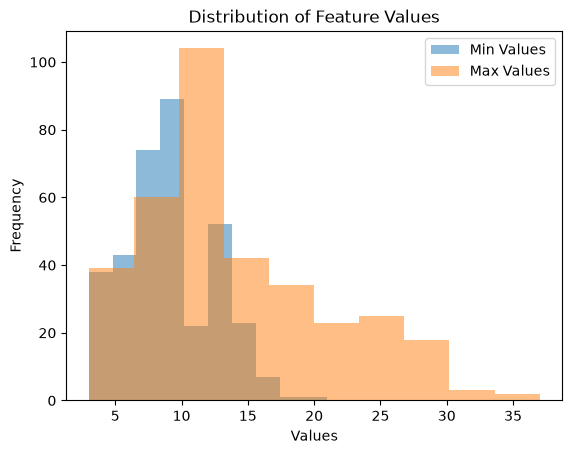

In [132]:
mypath = "../data/MRI/Axial"
sigma = 1

file = [f for f in listdir(mypath) if isfile(join(mypath, f))]
mins = []
maxs = []
for f in file:
    brain_vol = nib.load(join(mypath, f))
    brain_vol_data = brain_vol.get_fdata()

    filt = ndi.gaussian_filter(brain_vol_data, sigma=sigma)
    filt_hist = ndi.histogram(filt, min=0, max=np.max(filt), bins=50)

    gr = np.gradient(filt_hist)
    idx1, _ = find_peaks(gr, distance=1)
    idx2, _ = find_peaks(-gr, distance=1)
    idx = np.sort(np.array([idx1[:4], idx2[:4]]).flatten())

    mins.append(idx[1])
    mins.append(idx[2])
    maxs.append(idx[2]-1)
    maxs.append(idx[4])

plt.hist(mins, alpha=0.5, label='Min Values')
plt.hist(maxs, alpha=0.5, label='Max Values')
plt.xlabel('Values')
plt.ylabel('Frequency')
plt.title('Distribution of Feature Values')
plt.legend()
plt.show()